### **WK 5 Final Project**

Student Name: Aeran Lee

## Statistical Analysis and Machine Learning Workflow

**Proposed Prediction Problem**

The goal of this project is to develop a binary classification machine learning model to predict whether death was observed during follow-up among patients with primary biliary cirrhosis. Demographic, clinical, and laboratory variables will be evaluated to identify potential predictors associated with observed mortality status and to develop predictive models.To meet the assignment's binary classification requirement, the original three-category Status variable was recoded into a binary outcome variable, `Death_Outcome.`

**Target Variable**

The target variable, `Death_Outcome`, was derived from the original Status variable as follows:

1 = Death observed: Patients with documented death during follow-up (D).

0 = No death observed: Patients whose observations were censored (C) or censored due to liver transplantation (CL).

Importantly, censored observations do not necessarily indicate long-term survival. In addition, the binary outcome does not account for differences in follow-up duration or the competing event of liver transplantation.

Therefore, this project focuses on predicting observed death status during follow-up rather than mortality risk at a fixed time point. The results will be interpreted within these limitations.


# Statistical Analysis and Machine Learning Workflow

### Step 1: Data Loading and Exploratory Data Analysis (EDA)

- Load and validate the dataset.
- Examine dataset structure, variable types, and summary statistics.
- Identify missing values and assess data quality.
- Explore the distributions of numerical and categorical variables.
- Generate visualizations, including histograms, boxplots, and correlation heatmaps.
- Identify potential outliers and examine relationships among variables.

### Step 2: Inferential Statistical Analysis

- Select appropriate statistical methods based on the research questions and variable types.
- Define the null and alternative hypotheses.
- Perform inferential statistical tests to examine relationships between predictors and the outcome.
- Report statistical results, including test statistics, p-values, and confidence intervals when appropriate.
- Interpret findings in relation to the outcome and their potential clinical significance.
- Avoid using findings from the held-out test data to guide predictive model development.

### Step 3: Data Splitting and Preprocessing

- Define the target variable (y) and candidate predictors (X).
- Exclude identifiers and outcome-related variables to prevent data leakage.
- Split the dataset into training (80%) and testing (20%) sets using stratified sampling.
- Assess class imbalance in the training dataset.
- Identify numerical and categorical predictors.
- Handle missing values using appropriate imputation strategies.
- Standardize numerical variables and encode categorical variables.
- Build and validate preprocessing pipelines using training data only.
- Apply the fitted preprocessing transformations consistently to testing data.

### Step 4: Supervised Machine Learning

- Develop all supervised classification models required by the assignment.
- Integrate preprocessing and classification models into reproducible pipelines.
- Train models using the training dataset.
- Apply appropriate cross-validation methods.
- Address class imbalance using techniques such as class weighting or SMOTE when appropriate.
- Perform hyperparameter tuning when applicable.
- Use consistent training procedures to support fair model comparison.

### Step 5: Model Evaluation and Comparison

- Define reusable evaluation functions for consistent model assessment.
- Evaluate model performance using the held-out test dataset.
- Calculate accuracy, precision, recall, F1-score, and ROC-AUC.
- Generate confusion matrices and ROC curves.
- Compare training and testing performance to assess potential overfitting.
- Compare classification models using consistent evaluation metrics.
- Identify the best-performing model based on a prespecified primary evaluation metric.

### Step 6: Interpretation of Findings and Reproducibility

- Summarize key findings from inferential statistical analyses.
- Interpret model performance and identify important predictors using appropriate interpretation methods.
- Discuss potential clinical implications of the findings.
- Identify study limitations, including missing data, class imbalance, potential bias, and generalizability.
- Provide recommendations for future research and model improvement.
- Set random seeds where applicable to support reproducibility.
- Document data preprocessing, statistical methods, and modeling decisions.
- Ensure the notebook executes sequentially from start to finish.
- Record required Python libraries and dependencies.
- Provide a README with instructions for reproducing the analysis.

Step 1: Data Prepraration - Data Selection
---
**Dataset:**
Cirrhosis Patient Survival Prediction dataset from UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1)
`cirrhosis.csv`

**Description:**
This dataset contains data from 418 patients with cirrhosis. It includes variable that can be used to examine patient outcomes and explore potential predictors of mortality.

**Notebook Purpose:**
The purpose of this notebook is to examine and justify the selection of a dataset by exploring its structure, variables, and overal data quality in preparation for implementing a complete analytical pipeline for the final project.

**Reason for data selection:**
I selected this dataset to evaluate whether demographic, clinical, and laboratory variables can predict whether death was observed during follow-up among patients with primary biliary cirrhosis.

The dataset include multiple clinical variables that may be associated with patient outcomes. I am particularly interested in identifying which variables are most strongly associated with mortality among patients with cirrhosis. By applying machine learning methods, I hope to identify important predictors of observed mortality and better understand how clinical data can be used for mortality risk prediction.  

**Project criteria:**
The primary outcome variable is Status, which includes three categories: D (death), C (censored), and CL (censored due to liver transplantation).

To satisfy the assignment requirement for binary classification, I plan to combine C and CL into a single category representing patients without observed death during follow - up, while D will represent patients with observed death. However, censoring does not necessarily indicate survival, and this distiction will be acknowledged as a limitation of the binary classficastion approach.

The dataset contains 418 observations and 17 variables, satisfying the assignment requirements of at least 300 observations and predictor variables, subject to confirmation of the number of usable predictors after data processing.

In [170]:
# @title Step 1: Dataset Preparation | Exploration

from google.colab import files
import pandas as pd
import io
from pathlib import Path

# Update dataset
uploaded = files.upload()

# Ensure exactly one file is uploaded
if len(uploaded) !=1:
  raise ValueError("Please upload exactly one data file.")

# Identify uploaded file
filename = next(iter(uploaded))
extension = Path(filename).suffix.lower()
file_data = io.BytesIO(uploaded[filename])

# Load data based on file format
if extension in [".csv", ".tsv", ".txt"]:
    # Automatically detect the delimiter.
    df = pd.read_csv(file_data, sep=None, engine="python")

elif extension in [".xlsx", ".xls"]:
    # Load the first worksheet.
    df = pd.read_excel(file_data)

elif extension == ".json":
    df = pd.read_json(file_data)

elif extension == ".parquet":
    df = pd.read_parquet(file_data)

else:
    raise ValueError(
        f"'{extension}' files require a different reader. "
        "Supported format: CSV, TSV, TXT, XLSX, XLS, JSON, and Parquet."
    )

# Verify succesful loading
print(f"Succesfully loaded: {filename}")
print(f"Rows: {df.shape[0]} | Columns {df.shape[1]}")

display(df.head())


Saving cirrhosis.csv to cirrhosis (14).csv
Succesfully loaded: cirrhosis (14).csv
Rows: 418 | Columns 20


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [171]:
# @title Step 1: Data Preparation | Inspect Dataset Variables

attribute_list = list(df.columns)
print("Variables in the dataset:")
print("")
print(attribute_list)

Variables in the dataset:

['ID', 'N_Days', 'Status', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


In [172]:
# @title Step 1: Data Preparation | Check Dataset Dimension (Rows and Columns)

print("Number of rows and columns")
print("")
df.shape # (rows, colums)

Number of rows and columns



(418, 20)

In [173]:
# @title Step 1: Data Preparation | Inpect Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    object 
 3   Drug           312 non-null    object 
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    object 
 6   Ascites        312 non-null    object 
 7   Hepatomegaly   312 non-null    object 
 8   Spiders        312 non-null    object 
 9   Edema          418 non-null    object 
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombi

In [174]:
# @title Step 1: Data Preparation | Generate Descriptive Statistics and Variable Summary

# Describe all columns
summary = df.describe(include='all').T

# Insert formatted variable name + data type
summary.insert(
    0,
    'Variable',
    [f"<b>{col}</b><br><span style = 'font-weight:normal; font-size:smaller;'>[{df[col].dtype}]</span>" for col in summary.index]
)

# Reset index to clean up formatting
summary.reset_index(drop=True, inplace=True)

# Format numeric columns to 3 decimal places only
styled_summary = (
    summary.style
    .format(precision=3, na_rep="NA") # Format numbers to 3 decimals
    .set_table_styles([
        {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-aligh', 'center')]},
        {'selector': 'td', 'props': [('text-aligh', 'center')]}
    ])
    .hide(axis='index') #remove default row index
)

styled_summary

Variable,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID[int64],418.000,NA,NA,NA,209.500,120.810,1.000,105.250,209.500,313.750,418.000
N_Days[int64],418.000,NA,NA,NA,1917.782,1104.673,41.000,1092.750,1730.000,2613.500,4795.000
Status[object],418,3,C,232,NA,NA,NA,NA,NA,NA,NA
Drug[object],312,2,D-penicillamine,158,NA,NA,NA,NA,NA,NA,NA
Age[int64],418.000,NA,NA,NA,18533.352,3815.845,9598.000,15644.500,18628.000,21272.500,28650.000
Sex[object],418,2,F,374,NA,NA,NA,NA,NA,NA,NA
Ascites[object],312,2,N,288,NA,NA,NA,NA,NA,NA,NA
Hepatomegaly[object],312,2,Y,160,NA,NA,NA,NA,NA,NA,NA
Spiders[object],312,2,N,222,NA,NA,NA,NA,NA,NA,NA
Edema[object],418,3,N,354,NA,NA,NA,NA,NA,NA,NA


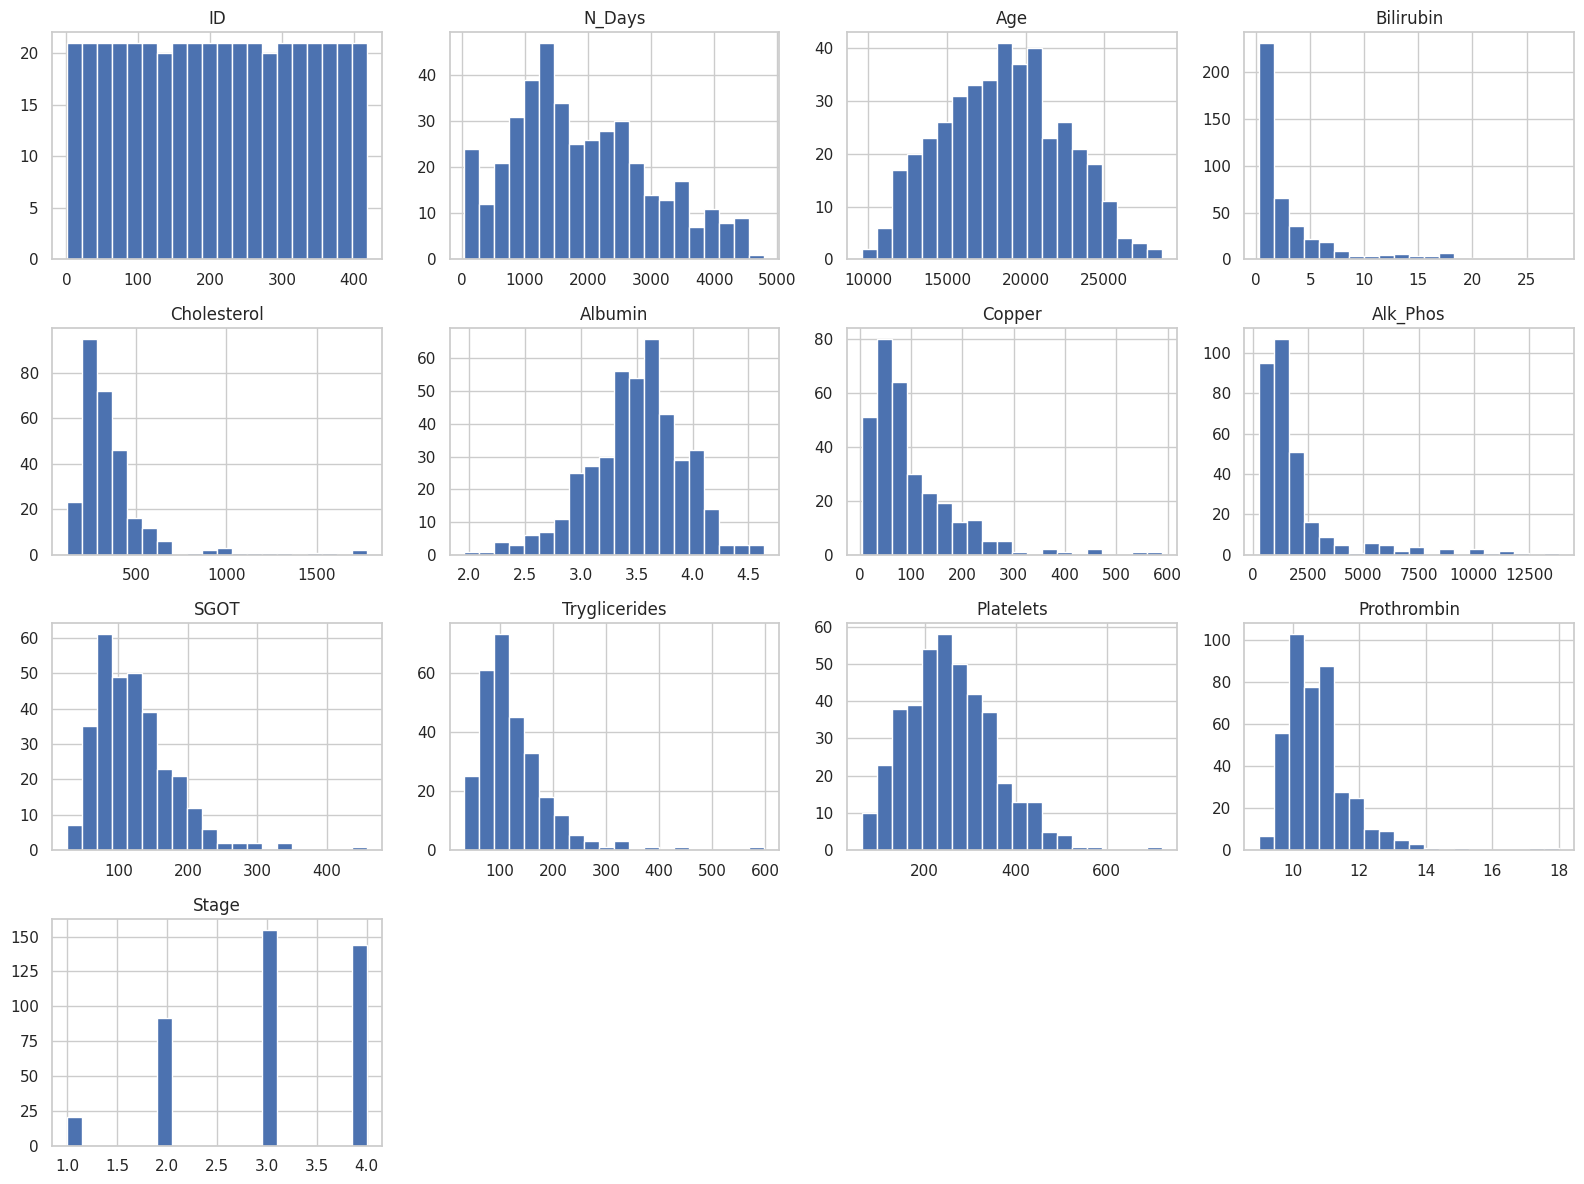

In [175]:
# @title Step 1: Data Preparation | exploratory visualization #1 Generate histograms for all numerical variables
import seaborn as sns
import matplotlib.pyplot as plt

df.hist(figsize=(16,12), bins=20)
plt.tight_layout()
plt.show()

In [176]:
# @title Step 1 : Data Preparation | Summarize Non-Missing and Missing Values by Variable

# Count non-null and missing responses
response_counts = df.count()
missing_counts = df.isnull().sum()

# Combine into one DataFrame
df_count = pd.DataFrame({
    'Variable': response_counts.index,
    '# of Responses': response_counts.values,
    '# Missing': missing_counts.values
})

# Display as styled table: bold headers and center-aligned values
df_count.style.set_table_styles([
    {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]}
])

,Variable,# of Responses,# Missing
0,ID,418,0
1,N_Days,418,0
2,Status,418,0
3,Drug,312,106
4,Age,418,0
5,Sex,418,0
6,Ascites,312,106
7,Hepatomegaly,312,106
8,Spiders,312,106
9,Edema,418,0


In [177]:
# @title Step 1 : Data Preparation | Convert Data Types and Age Units

# Convert ID and N_Days to Object
df["ID"] = df["ID"].astype("object")
df["N_Days"] = df["N_Days"].astype("object")

# Convert Age from days to years
df["Age"] = df["Age"]/365.25


# change numerical variable to categorical variables
# # 1 = D- penicillamine
# 0 = Placebo

df["Drug"] = df["Drug"].map({
    "D-penicillamine": "1",
    "Placebo": "0"
})

# Stage variable numeric --> categorical
df["Stage"] = pd.Categorical(
    df["Stage"],
    categories=[1, 2, 3, 4],
    ordered=True
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   ID             418 non-null    object  
 1   N_Days         418 non-null    object  
 2   Status         418 non-null    object  
 3   Drug           312 non-null    object  
 4   Age            418 non-null    float64 
 5   Sex            418 non-null    object  
 6   Ascites        312 non-null    object  
 7   Hepatomegaly   312 non-null    object  
 8   Spiders        312 non-null    object  
 9   Edema          418 non-null    object  
 10  Bilirubin      418 non-null    float64 
 11  Cholesterol    284 non-null    float64 
 12  Albumin        418 non-null    float64 
 13  Copper         310 non-null    float64 
 14  Alk_Phos       312 non-null    float64 
 15  SGOT           312 non-null    float64 
 16  Tryglicerides  282 non-null    float64 
 17  Platelets      407 non-null    floa

In [178]:
# @title Step 1: Data Preparation | Identify and Replace Implausible Zero Values

import numpy as np

variables_to_replace_zeros = [
    'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT',
    'Tryglicerides', 'Platelets', 'Prothrombin'
]

# Validate required variables
missing_columns = [
    col for col in variables_to_replace_zeros
    if col not in df.columns
]

if missing_columns:
  raise ValueError(f"Missing required columns: {missing_columns}")

# Replace implausible zeros with NaN
for variable in variables_to_replace_zeros:
  zero_count = (df[variable]== 0).sum()

  df[variable] = df[variable].replace(0, np.nan)

  print(f"{variable}: {zero_count} zeros replaced with NaN")

print("\nData cleaning completed.")
print("Missing values will be imputed using training data in the ML pipeline.")

Bilirubin: 0 zeros replaced with NaN
Cholesterol: 0 zeros replaced with NaN
Albumin: 0 zeros replaced with NaN
Copper: 0 zeros replaced with NaN
Alk_Phos: 0 zeros replaced with NaN
SGOT: 0 zeros replaced with NaN
Tryglicerides: 0 zeros replaced with NaN
Platelets: 0 zeros replaced with NaN
Prothrombin: 0 zeros replaced with NaN

Data cleaning completed.
Missing values will be imputed using training data in the ML pipeline.


In [179]:
# @title Step 1: Data Preparation| Data Qualtiy Assessement, Automatically Identify Missing Values in Numeric Predictors

target_variable = "Death_Outcome"

# Automatically identify numeric predictors.
numeric_predictors = df.select_dtypes(include="number").columns
numeric_predictors = numeric_predictors.drop(
    target_variable, errors="ignore"
)

# Count missing values.
missing_counts = df[numeric_predictors].isna().sum()
predictors_with_missing = missing_counts[missing_counts > 0]

# Report missing values
if predictors_with_missing.empty:
    print("No missing values detected in numeric predictors.")
else:
    print("Numeric predictors requiring imputation:")
    display(predictors_with_missing.rename("Missing values").to_frame())

    print("\nMissing values identified but not yet imputed.")
    print("Imputation will be performed using training-set medians in the ML pipeline.")

Numeric predictors requiring imputation:


,Missing values
Cholesterol,134
Copper,108
Alk_Phos,106
SGOT,106
Tryglicerides,136
Platelets,11
Prothrombin,2



Missing values identified but not yet imputed.
Imputation will be performed using training-set medians in the ML pipeline.


In [180]:
# @title Step 1: Data pPeparation - Create binary mortality outcome

# Create binary mortality outcome
# 1 = Death observed
# 0 = No death observed during follow-up

df["Death_Outcome"] = df["Status"].map({
    "D": 1,
    "C": 0,
    "CL": 0
})

In [181]:

# @title Step 1: Data Preparation | Automated Data Validation

def validate_dataset(df):

    # 1. Check required columns
    required_cols = [
        "ID", "Status", "Death_Outcome",
        "Age", "Bilirubin", "Albumin"
    ]

    missing_cols = [
        col for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}"
        )

    # 2. Check duplicate patient IDs
    duplicates = df["ID"].duplicated().sum()

    if duplicates > 0:
        raise ValueError(
            f"Found {duplicates} duplicate patient IDs."
        )

    # 3. Validate original outcome categories
    valid_status = {"D", "C", "CL"}

    if not df["Status"].isin(valid_status).all():
        raise ValueError(
            "Status contains missing or unexpected values."
        )

    # 4. Validate binary outcome
    if df["Death_Outcome"].isna().any():
        raise ValueError("Outcome contains missing values.")

    if set(df["Death_Outcome"].unique()) != {0, 1}:
        raise ValueError(
            "Outcome must contain both classes: 0 and 1."
        )

    # 5. Check age values
    age = pd.to_numeric(df["Age"], errors="coerce")

    if age.isna().any() or (age <= 0).any():
        raise ValueError(
            "Age contains missing, nonnumeric, or invalid values."
        )

    # 6. Detect class imbalance
    death_rate = df["Death_Outcome"].mean()

    if death_rate < 0.20 or death_rate > 0.80:
        print("Warning: Substantial class imbalance detected.")
    else:
        print("Both outcome classes are represented.")

    # 7. Confirm validation
    print("\nData validation completed successfully.")
    print(f"Total patients: {len(df)}")
    print(f"Duplicate IDs: {duplicates}")
    print(f"Observed death proportion: {death_rate:.1%}")

    return True


validate_dataset(df)


Both outcome classes are represented.

Data validation completed successfully.
Total patients: 418
Duplicate IDs: 0
Observed death proportion: 38.5%


True

**Data Quality Assessment**

1. Missing Values and Data Quality
The dataset contains 418 observations, with missing values identified in 12 variables. Triglycerides (282 missing), cholesterol (284 missing) have the highest percentages of missing data, followed by copper. Several other clinical variables, including ascietes, hepatomegaly, spiders, alkaline phosphatase, and SGOT, have 106 missing values. In contrast, the outcome variable (Death_outcome) has no missing observations.

2. Anticipated Preprocessing Steps
Missing numerical values will be handled using medican imputation, while missing categorical values will be handled using appropriate categorical imputation methods. Patient ID and N_Days will be excluded from the baseline prediction model to avoid using idenifiers and follow- up information predictors. Age has been converted from days to years for easier clinical interpretation. Categorical predictors will be encoded, and numerical predictors will be scaled as needed. Data preprocessing will be fitted using the training dataset to minimize data leakage.

3. Potential challenges
The relatively small sample size and substantial missingness in several clinical variables may affect model performance and generalizability. The repeated pattern of 106 missing observations across multiple variables suggests possible systematic missingness that requires further investigation. Skewed laboratory values and potential class imbalacne may also influence model performance.
Another liitation is the binary outcome definition. Combiming ceonsored patients and patients cencered due to liver transplatation into a single category does not account for differences in follow-up duration or the competing event of liver tranplantation. Therefore, the model will predict observed mortaility status rather than true survival probability.

Death_Outcome
0    257
1    161
Name: count, dtype: int64


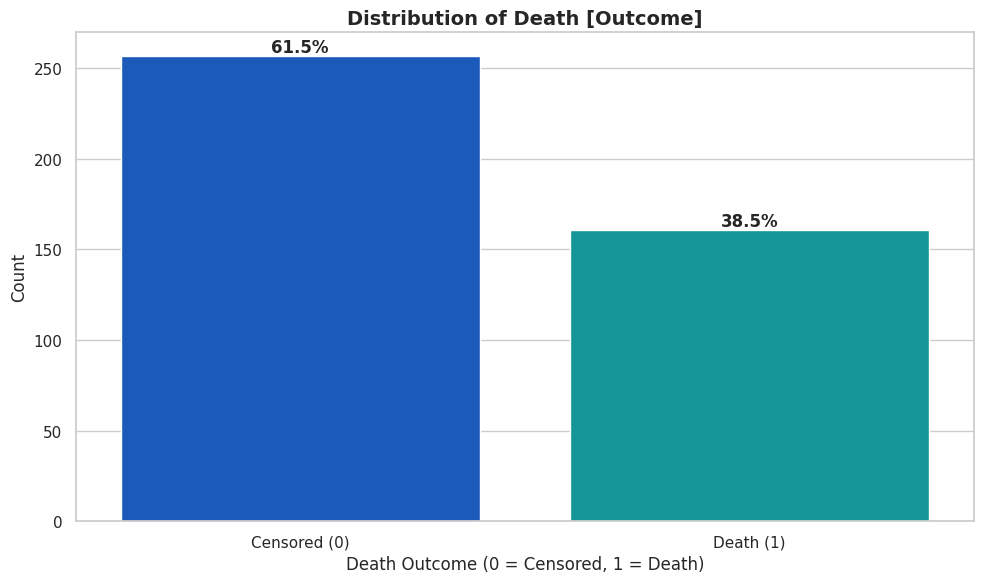

In [182]:
# @ title Step 1 : Data preparation | Function to annotate bars with percentage labels

# Verify the distribution
print(df["Death_Outcome"].value_counts(dropna=False))

def annotate_bars(ax, series):
    total = len(series)
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height() / total)
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(
            percentage,
            (x, y),
            ha='center',
            va='bottom',
            fontsize=12,
            fontweight='bold'
        )

# Plot distribution of Outcome
fig, ax = plt.subplots(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Death_Outcome',
    hue='Death_Outcome',
    palette='winter',
    legend=False,
    ax=ax
)

annotate_bars(ax, df['Death_Outcome'])

ax.set_title('Distribution of Death [Outcome]', fontsize=14, fontweight='bold')
ax.set_xlabel('Death Outcome (0 = Censored, 1 = Death)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Censored (0)', 'Death (1)'], fontsize=11)

plt.tight_layout()
plt.show()

### Step 2: Inferential statistical analysis
Correlations are ndescritive and do not establish causation. The following heatmaps use the full dataset for exploration; they must not be used to select predictors for the held-out test evaluation.

In [183]:
# @title Step 2: Inferential statistical analysis | Spearman's Rank Correaltion Matrix for death_outcome vs all numerical variables.

# Spearman's Correaltion Coefficient will be used to determine what variables strongly attribute to Death_outcome as it's
## non-parametric, monotonic relationship; variable tend to move in the same direction, but not necessarily at a constant rate and,
## more robust to outliner because it operates on ranks rather than raw values.

# Spearman's Rank Correlation Matrix
df.select_dtypes(include='number').corr(method='spearman')

,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Death_Outcome
Age,1.000000,-0.032670,-0.172545,-0.166049,-0.003505,-0.145766,-0.182614,0.021726,-0.156162,0.112490,0.235366
Bilirubin,-0.032670,1.000000,0.402454,-0.336671,0.628365,0.357698,0.586320,0.360860,-0.174110,0.273056,0.486373
Cholesterol,-0.172545,0.402454,1.000000,-0.027747,0.225713,0.432986,0.372697,0.379729,0.265973,-0.153252,0.147027
Albumin,-0.166049,-0.336671,-0.027747,1.000000,-0.298269,-0.185430,-0.236190,-0.076428,0.178427,-0.187587,-0.242283
Copper,-0.003505,0.628365,0.225713,-0.298269,1.000000,0.280944,0.404484,0.323688,-0.080026,0.209292,0.406555
Alk_Phos,-0.145766,0.357698,0.432986,-0.185430,0.280944,1.000000,0.407436,0.237550,0.169578,0.090527,0.263361
SGOT,-0.182614,0.586320,0.372697,-0.236190,0.404484,0.407436,1.000000,0.133526,-0.080905,0.136189,0.305636
Tryglicerides,0.021726,0.360860,0.379729,-0.076428,0.323688,0.237550,0.133526,1.000000,0.074150,-0.093405,0.176949
Platelets,-0.156162,-0.174110,0.265973,0.178427,-0.080026,0.169578,-0.080905,0.074150,1.000000,-0.225543,-0.148622
Prothrombin,0.112490,0.273056,-0.153252,-0.187587,0.209292,0.090527,0.136189,-0.093405,-0.225543,1.000000,0.403802


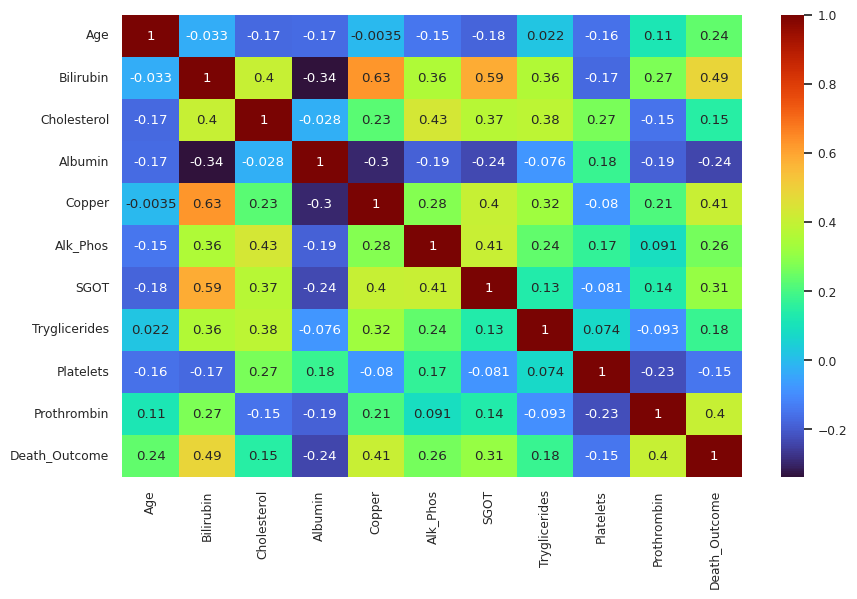

In [184]:
# @title Step 2: Inferential statistical analysis - Spearman's Rank Correlation Heatmap (cmap=turbo)
plt.figure(figsize=(10,6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5
sns.heatmap(df.select_dtypes(include='number').corr(method='spearman'), annot=True, cmap = "turbo");
plt.show();

In [185]:
# @title Step 2: Inferential statistical analysis - Phi-K Correaltion Coefficeint for Death_outcome vs categorical variables

%pip install phik
import phik
from phik import resources, report

In [186]:
# @title Step 2: Inferential statistical analysis - | Phi-K Correaltion Matrix
df.phik_matrix()

interval columns not set, guessing: ['Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Death_Outcome']


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,...,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Death_Outcome
ID,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
N_Days,1.0,1.000000,0.882525,0.505259,0.871803,0.000000,0.000000,0.926773,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.919994,0.914171,0.744558,0.734663
Status,1.0,0.882525,1.000000,0.000000,0.341194,0.058045,0.194729,0.200845,0.132697,0.510179,...,0.246178,0.317187,0.623296,0.216494,0.458681,0.240812,0.237334,0.422938,0.237949,1.000000
Drug,1.0,0.505259,0.000000,1.000000,0.146248,0.000000,0.000000,0.122688,0.000000,0.000000,...,0.000000,0.000000,0.045611,0.000000,0.000000,0.000000,0.000000,0.000000,0.109528,0.000000
Age,1.0,0.871803,0.341194,0.146248,1.000000,0.156702,0.289157,0.000000,0.000000,0.233585,...,0.000000,0.000000,0.195713,0.000000,0.182597,0.000000,0.126047,0.126004,0.163813,0.283044
Sex,1.0,0.000000,0.058045,0.000000,0.156702,1.000000,0.000000,0.000000,0.183609,0.000000,...,0.000000,0.000000,0.271250,0.067839,0.000000,0.057989,0.000000,0.089606,0.000000,0.145543
Ascites,1.0,0.000000,0.194729,0.000000,0.289157,0.000000,1.000000,0.215173,0.213595,0.393734,...,0.000000,0.631101,0.273578,0.000000,0.057573,0.297338,0.294569,0.482581,0.453785,0.470225
Hepatomegaly,1.0,0.926773,0.200845,0.122688,0.000000,0.000000,0.215173,1.000000,0.429771,0.094630,...,0.070982,0.391609,0.244206,0.236416,0.146336,0.195823,0.258021,0.397093,0.668587,0.455914
Spiders,1.0,0.000000,0.132697,0.000000,0.000000,0.183609,0.213595,0.429771,1.000000,0.158574,...,0.000000,0.296781,0.252113,0.125542,0.233285,0.185151,0.247012,0.363735,0.423100,0.332793
Edema,1.0,0.000000,0.510179,0.000000,0.233585,0.000000,0.393734,0.094630,0.158574,1.000000,...,0.000000,0.429141,0.512887,0.167043,0.350950,0.270834,0.243971,0.428479,0.182291,0.183232


interval columns not set, guessing: ['Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Death_Outcome']


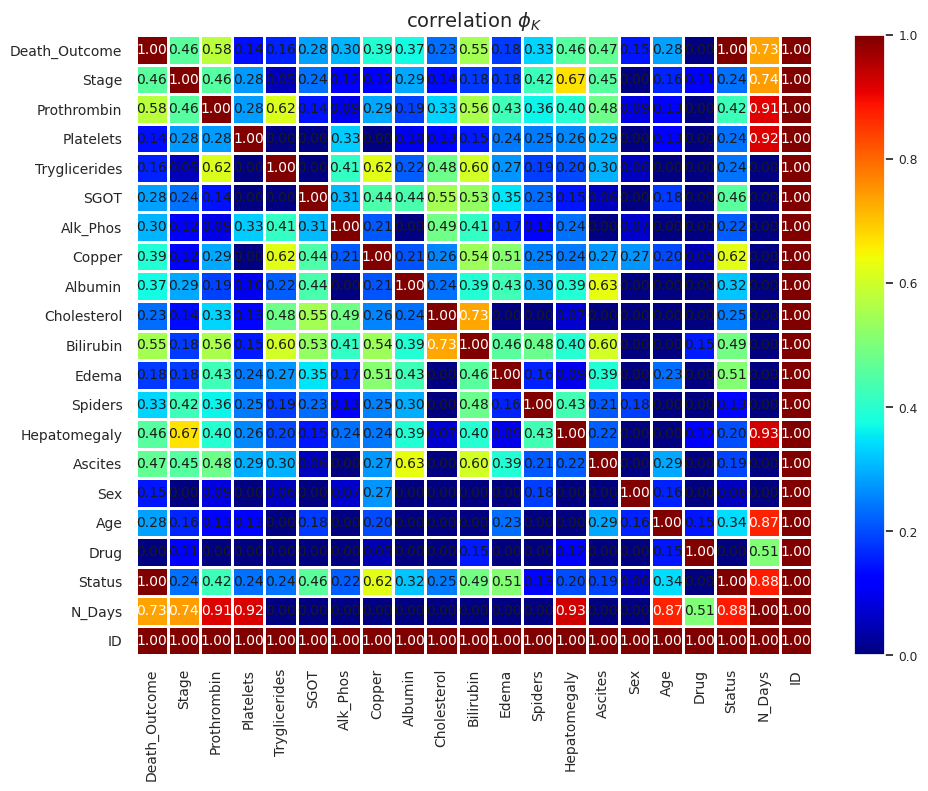

In [187]:
# @title Step 2: Inferential statistical analysis | Phi-K Correlation Heatmap (cmap=jet)
from phik.report import plot_correlation_matrix
phik_overview = df.phik_matrix()

plot_correlation_matrix(phik_overview.values,
                        x_labels=phik_overview.columns,
                        y_labels=phik_overview.index,
                        vmin=0, vmax=1, color_map="jet",
                        title=r"correlation $\phi_K$",
                        fontsize_factor=1.0,
                        figsize=(10, 8))
plt.tight_layout()
plt.show()


### Mann–Whitney U Test — Mathematical Formula

The Mann–Whitney U test is a nonparametric statistical method used to compare bilirubin distributions between patients with observed mortality (Outcome = 1) and those without observed mortality (Outcome = 0).

The test statistic is calculated as:

$$
U_1 = n_1n_2 + \frac{n_1(n_1+1)}{2} - R_1
$$

Where:

- $n_1$ = Number of patients in group 1
- $n_2$ = Number of patients in group 2
- $R_1$ = Sum of ranks for group 1

The test evaluates the following hypotheses:

- **Null hypothesis ($H_0$):** Bilirubin distributions are equal between the two outcome groups.
- **Alternative hypothesis ($H_1$):** Bilirubin distributions differ between the two outcome groups.

A p-value below 0.05 indicates statistically significant evidence against the null hypothesis. However, statistical significance does not establish causation.



### Inferential Statistical Analysis
Research Question: Which clinical characteristics are associated with obvvserved death status?

Null hypothesis (H0): Each adjusted predictor coefficient is zero (odds ratio = 1).
Alternative hypothesis (H1): At least one predictor has a nonzero adjusted coefficeint.

These are explatory associate3ion, not causal effects. The exissting full-dataset inference belwo is descriptive/exploratory only and must not guide predictive feature selection or hyperparameter tuning. For confirmatory inference independent of the held-out test set, repeat these analyses on training data after split.

In [188]:
# =============================================================================
# INFERENTIAL STATISTICS LIBRARIES
# =============================================================================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings("ignore")

In [189]:
# @title Step 2a: Inferential statistical analysis | Multivariable Logistic Regression - all predictors

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Exclude identifier, follow-up time, original outcome
exclude_cols = [
    "ID", "N_Days", "Status", "Death_Outcome", "Stage"
]

analysis_df = df.drop(
    columns=exclude_cols,
    errors="ignore"
).copy()

analysis_df["Death_Outcome"] = df["Death_Outcome"]

# Define categorical predictors
categorical_cols = [
    "Sex", "Drug", "Ascites",
    "Hepatomegaly", "Spiders",
    "Edema"
]

categorical_cols = [
    col for col in categorical_cols
    if col in analysis_df.columns
]

# Create model formula
predictors = [
    col for col in analysis_df.columns
    if col != "Death_Outcome"
]

terms = [
    f"C({col})" if col in categorical_cols else col
    for col in predictors
]

formula = "Death_Outcome ~ " + " + ".join(terms)

# Complete-case analysis
model_df = analysis_df.dropna()

print("Total observations:", len(analysis_df))
print("Complete observations:", len(model_df))
print("Predictors:", predictors)

# Fit model
model = smf.logit(
    formula=formula,
    data=model_df
).fit(maxiter=1000)

# Adjusted odds ratios
results = pd.DataFrame({
    "Adjusted OR": np.exp(model.params),
    "95% CI Lower": np.exp(model.conf_int()[0]),
    "95% CI Upper": np.exp(model.conf_int()[1]),
    "P-value": model.pvalues
})

display(results.round(3))

Total observations: 418
Complete observations: 276
Predictors: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
Optimization terminated successfully.
         Current function value: 0.435243
         Iterations 7


,Adjusted OR,95% CI Lower,95% CI Upper,P-value
Intercept,0.000,0.000,0.003,0.000
C(Drug)[T.1],1.274,0.657,2.470,0.473
C(Sex)[T.M],1.679,0.609,4.631,0.317
C(Ascites)[T.Y],3.267,0.229,46.517,0.382
C(Hepatomegaly)[T.Y],1.341,0.660,2.724,0.417
C(Spiders)[T.Y],1.534,0.712,3.302,0.274
C(Edema)[T.S],1.023,0.321,3.257,0.970
C(Edema)[T.Y],2.233,0.134,37.312,0.576
Age,1.053,1.017,1.091,0.003
Bilirubin,1.158,0.986,1.359,0.073


### Interpretation

Spearman's rank correlation analysis identified moderate positive correlations between Death_Outcome and several numerical variables, including Bilirubin (ρ = 0.49), Copper (ρ = 0.41), and Prothrombin (ρ = 0.40). Phi-K correlation analysis also identified notable associations between Death_Outcome and Prothrombin (φk = 0.58), Bilirubin (φk = 0.55), Ascites (φk = 0.47), Stage (φk = 0.46), and Hepatomegaly (φk = 0.46).

However, the logistic regression analysis showed different results. Only Age (p = 0.003), Alkaline Phosphatase (p = 0.003), and Prothrombin (p = 0.003) were statistically significant at the 0.05 significance level. These findings suggest that although several variables demonstrated moderate associations with mortality status in the correlation analyses, not all remained statistically significant in the logistic regression model.

This difference may reflect overlapping information among predictors, potential confounding, or differences between unadjusted correlation analyses and multivariable logistic regression. Therefore, correlation strength alone should not determine the statistical significance or predictive importance of a variable.


### Step 2b: Inferential statistical analysi | Mann -Whitney U Test

Although logistic regression did not identify a statistically significant association between bilirubin and death outcome, Spearman's rank correlation suggested a strong association. Because bilirubin was not normally distributed, the Mann–Whitney U test was selected as a secondary inferential statistical analysis to compare bilirubin distributions between the death and censored groups.

Mann-Whitney U Test — Bilirubin by Outcome
  Censored (0): n=257, median=1.000, IQR=[0.700, 1.800]
  Death   (1): n=161, median=3.200, IQR=[1.400, 7.100]
  U = 8760.5
  p-value = 0.0000
  Rank-biserial r = 0.577  (large)

  ✓ Reject H₀ — Bilirubin distributions differ significantly between groups


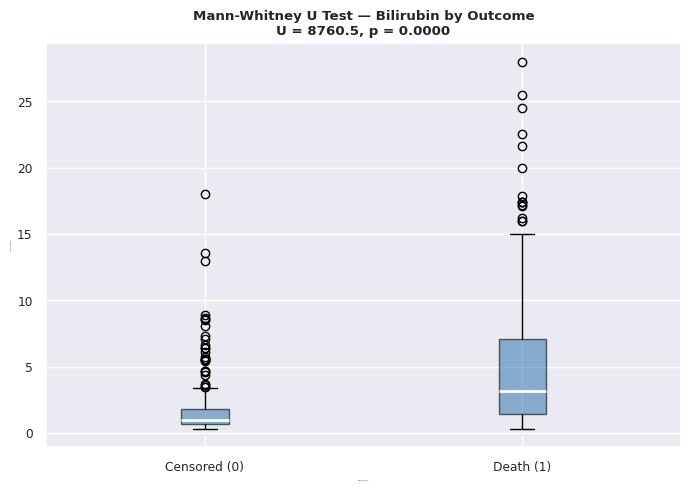

In [190]:
# =============================================================================
# NONPARAMETRIC TEST 1: MANN-WHITNEY U TEST
# =============================================================================
# Nonparametric alternative to the independent t-test.
# Tests whether Bilirubin distributions differ between Outcome groups.
#
# Test statistic:
#
#   U₁ = n₁n₂ + n₁(n₁+1)/2 - R₁
#   U  = min(U₁, U₂)
#
#   where R₁ = sum of ranks assigned to group 1
#
# For large samples:
#   z = (U - n₁n₂/2) / √(n₁n₂(n₁+n₂+1)/12)
#
# H₀: Bilirubin distributions are equal across outcome groups.
# H₁: Billirubin distributions differ between outcome groups.
# =============================================================================

group0 = df[df['Death_Outcome'] == 0]['Bilirubin'].dropna()
group1 = df[df['Death_Outcome'] == 1]['Bilirubin'].dropna()

u_stat, p_val = stats.mannwhitneyu(group0, group1, alternative='two-sided')

# Effect size: rank-biserial correlation
n0, n1 = len(group0), len(group1)
r_rb = 1 - (2 * u_stat) / (n0 * n1)

print("Mann-Whitney U Test — Bilirubin by Outcome")
print(f"  Censored (0): n={n0}, median={group0.median():.3f}, "
      f"IQR=[{group0.quantile(.25):.3f}, {group0.quantile(.75):.3f}]")
print(f"  Death   (1): n={n1}, median={group1.median():.3f}, "
      f"IQR=[{group1.quantile(.25):.3f}, {group1.quantile(.75):.3f}]")
print(f"  U = {u_stat:.1f}")
print(f"  p-value = {p_val:.4f}")
print(f"  Rank-biserial r = {r_rb:.3f}  "
      f"({'small' if abs(r_rb)<0.3 else 'medium' if abs(r_rb)<0.5 else 'large'})")
print()
if p_val < 0.05:
    print("  ✓ Reject H₀ — Bilirubin distributions differ significantly between groups")
else:
    print("  ✗ Fail to reject H₀ — no significant distributional difference in Bilirubin")

# Visualization
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([group0, group1],
           labels=['Censored (0)', 'Death (1)'],
           patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.6),
           medianprops=dict(color='white', linewidth=2))
ax.set_title(f'Mann-Whitney U Test — Bilirubin by Outcome\n'
             f'U = {u_stat:.1f}, p = {p_val:.4f}', fontweight='bold')
ax.set_xlabel('Death_Outcome')
ax.set_ylabel('Bilirubin (mg/dL)')
plt.tight_layout()
plt.show()

The Mann–Whitney U test is a nonparametric alternative
to the independent t-test. It was selected to compare
bilirubin distributions between the censored and death
groups because bilirubin was not normally distributed.

The test statistic is calculated as:

$$
U_1 = n_1n_2 + \frac{n_1(n_1+1)}{2} - R_1
$$

Where:
- $n_1$ = Sample size of group 1
- $n_2$ = Sample size of group 2
- $R_1$ = Sum of ranks for group 1

**Hypotheses:**

- $H_0$: Bilirubin distributions are equal between groups.
- $H_1$: Bilirubin distributions differ between groups.

**Results and Interpretation:**

The Mann–Whitney U test identified a statistically significant difference in bilirubin distributions between the censored and death groups (U = 8760.5, p < 0.001).

The death group had a higher median bilirubin level (3.2) compared with the censored group (1.0). Therefore, the null hypothesis was rejected.



The Mann–Whitney U test revealed a statistically significant difference in bilirubin distributions between the censored and death groups (U = 8760.5, p < 0.001), leading to rejection of the null hypothesis. The death group had a higher median bilirubin level (3.2, IQR: 1.4–7.1) compared with the censored group (1.0, IQR: 0.7–1.8). The rank-biserial correlation (r = 0.577) indicated a large effect size, suggesting a substantial difference between the two groups.

However, the Mann–Whitney U test does not adjust for potential confounding variables, unlike multivariable logistic regression. Therefore, these findings indicate an unadjusted association between bilirubin levels and observed mortality status rather than an independent association with mortality risk.

### Step 3: Data splitting and Preprocessing
Create a stratified hold-out set, assess training-class imbalance, and fit all imputation, encoding, and scaling operations using training data only

In [191]:
# @title Step 3: Data splitting and Data preparation | Missing Data Assessment

import pandas as pd

# Assess missingness without modifying the original dataset
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing = missing[
    missing["Missing Count"] > 0
].sort_values("Missing %", ascending=False)

def flag_missing(pct):
    if pct < 5:
        return "Low — simple imputation may be reasonable"
    elif pct <= 20:
        return "Moderate — investigate missingness"
    else:
        return "High — investigate mechanism; consider imputation and indicators"

missing["Recommendation"] = missing["Missing %"].apply(flag_missing)

display(missing)

# Do not drop high-missingness columns at this stage. Generally more than 20% of missingess recommended missingness indicator plus drop column however,
# the majority of variables have significant missingness, if dropped, would not be able to build ML model.
# therefore, will use median method by using SimpleImputer(strategy="median")

,Missing Count,Missing %,Recommendation
Tryglicerides,136,32.54,High — investigate mechanism; consider imputat...
Cholesterol,134,32.06,High — investigate mechanism; consider imputat...
Copper,108,25.84,High — investigate mechanism; consider imputat...
Drug,106,25.36,High — investigate mechanism; consider imputat...
Spiders,106,25.36,High — investigate mechanism; consider imputat...
Hepatomegaly,106,25.36,High — investigate mechanism; consider imputat...
Ascites,106,25.36,High — investigate mechanism; consider imputat...
Alk_Phos,106,25.36,High — investigate mechanism; consider imputat...
SGOT,106,25.36,High — investigate mechanism; consider imputat...
Platelets,11,2.63,Low — simple imputation may be reasonable


In [192]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# @title Step 3 : Feature Selection | Train-Test Split & Class imbalance.

# Exclude identifiers and outcome-related information
X = df.drop(
    columns=["ID", "Status", "N_Days", "Death_Outcome"],
    errors="ignore"
)
y = df["Death_Outcome"]
assert y.notna().all(), "Target contains missing values"

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape, "Testing", X_test.shape)

Training: (334, 17) Testing (84, 17)


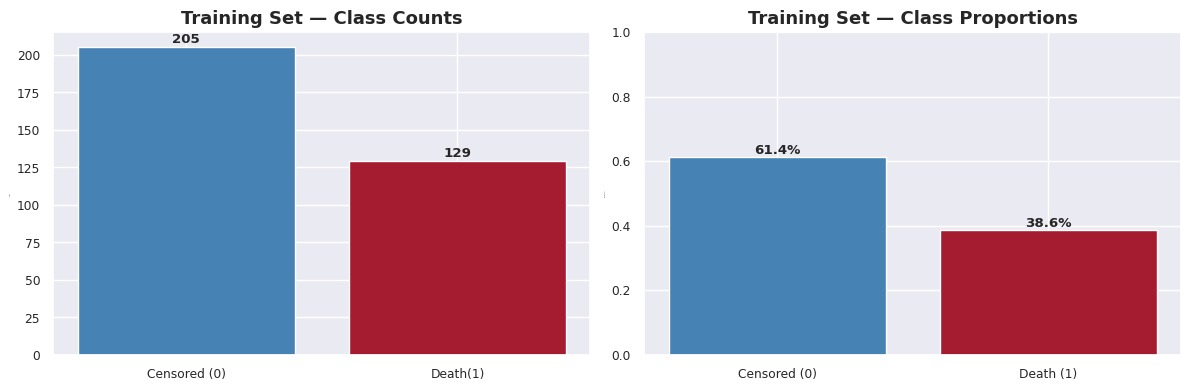

Imbalance ratio: 1.59
Strategy: class_weight='balanced' applied to all classifiers.
          SMOTE applied inside ImbPipeline for select models.


In [193]:
# @title Step 3: Feature Selection, Train - Test Split & Class imbalance

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class counts
counts = y_train.value_counts()
axes[0].bar(
    ['Censored (0)', 'Death(1)'],
    counts.values,
    color=['steelblue', '#A51C30'],
    edgecolor='white'
)
axes[0].set_title('Training Set — Class Counts', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontweight='bold')

# Class proportions
proportions = y_train.value_counts(normalize=True)
axes[1].bar(
    ['Censored (0)', 'Death (1)'],
    proportions.values,
    color=['steelblue', '#A51C30'],
    edgecolor='white'
)
axes[1].set_title('Training Set — Class Proportions', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Proportion')
axes[1].set_ylim(0, 1)
for i, v in enumerate(proportions.values):
    axes[1].text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"Imbalance ratio: {imbalance_ratio:.2f}")
print(f"Strategy: class_weight='balanced' applied to all classifiers.")
print(f"          SMOTE applied inside ImbPipeline for select models.")

In [194]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)
from sklearn.linear_model import LogisticRegression

# @title Step 3 : Data Splitting and Preprocessing


import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

numeric_cols = [
    'Age', 'Bilirubin', 'Cholesterol', 'Albumin',
    'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides',
    'Platelets', 'Prothrombin'
]

categorical_cols = [
    'Drug', 'Sex', 'Ascites', 'Hepatomegaly',
    'Spiders', 'Edema', 'Stage'
]

# Create clean copies
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Numeric: ensure numeric values and np.nan missing values
for col in numeric_cols:
    X_train_clean[col] = pd.to_numeric(
        X_train_clean[col], errors="raise"
    ).astype(float)

    X_test_clean[col] = pd.to_numeric(
        X_test_clean[col], errors="raise"
    ).astype(float)

# Categorical: convert to consistent string categories,
# preserving missing values as np.nan
for col in categorical_cols:
    for data in [X_train_clean, X_test_clean]:
        data[col] = data[col].map(
            lambda x: np.nan if pd.isna(x) else str(x)
        ).astype(object)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both branches
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Test preprocessing BEFORE model fitting
X_processed = preprocessor.fit_transform(X_train_clean)

print("Preprocessing successful!")
print("Processed shape:", X_processed.shape)





Preprocessing successful!
Processed shape: (334, 27)


In [195]:
# =============================================================================
# SHARED EVALUATION FUNCTIONS
# =============================================================================

def get_metrics_score(model, X_train, X_test, y_train, y_test, verbose=True):
    """
    Computes Accuracy, Recall, Precision, F1-score, and AUC-ROC
    for both training and test sets.

    Parameters
    ----------
    model    : fitted sklearn estimator or Pipeline
    X_train  : training feature matrix
    X_test   : test feature matrix
    y_train  : training target vector
    y_test   : test target vector
    verbose  : if True, prints results to console

    Returns
    -------
    list : [train_acc, test_acc, train_recall, test_recall,
            train_precision, test_precision, train_f1, test_f1,
            train_auc, test_auc]
    """
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    # Compute AUC-ROC (requires probability scores)
    if hasattr(model, 'predict_proba'):
        train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
        test_auc  = roc_auc_score(y_test,  model.predict_proba(X_test)[:, 1])
    elif hasattr(model, 'decision_function'):
        train_auc = roc_auc_score(y_train, model.decision_function(X_train))
        test_auc  = roc_auc_score(y_test,  model.decision_function(X_test))
    else:
        train_auc = test_auc = None

    train_acc  = accuracy_score(y_train, y_pred_train)
    test_acc   = accuracy_score(y_test,  y_pred_test)
    train_rec  = recall_score(y_train, y_pred_train)
    test_rec   = recall_score(y_test,  y_pred_test)
    train_prec = precision_score(y_train, y_pred_train)
    test_prec  = precision_score(y_test,  y_pred_test)
    train_f1   = f1_score(y_train, y_pred_train)
    test_f1    = f1_score(y_test,  y_pred_test)

    if verbose:
        print("=" * 50)
        print(f"{'Metric':<22} {'Train':>8}  {'Test':>8}")
        print("=" * 50)
        print(f"{'Accuracy':<22} {train_acc:>8.3f}  {test_acc:>8.3f}")
        print(f"{'Recall':<22} {train_rec:>8.3f}  {test_rec:>8.3f}")
        print(f"{'Precision':<22} {train_prec:>8.3f}  {test_prec:>8.3f}")
        print(f"{'F1-Score':<22} {train_f1:>8.3f}  {test_f1:>8.3f}")
        if train_auc is not None:
            print(f"{'AUC-ROC':<22} {train_auc:>8.3f}  {test_auc:>8.3f}")
        print("=" * 50)

    return [train_acc, test_acc, train_rec, test_rec,
            train_prec, test_prec, train_f1, test_f1,
            train_auc, test_auc]


def make_confusion_matrix(model, X, y_actual, title="Confusion Matrix"):
    """
    Generates a styled confusion matrix with counts and percentages.

    Parameters
    ----------
    model    : fitted sklearn estimator or Pipeline
    X        : feature matrix (e.g., X_test)
    y_actual : true class labels
    title    : plot title
    """
    y_predict = model.predict(X)
    cm = confusion_matrix(y_actual, y_predict)

    group_counts      = [f"{v:0.0f}" for v in cm.flatten()]
    group_percentages = [f"{v:.2%}"  for v in cm.flatten() / np.sum(cm)]
    labels = np.array([f"{c}\n{p}" for c, p in
                       zip(group_counts, group_percentages)]).reshape(2, 2)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=labels,
        fmt='',
        cmap='Blues',
        xticklabels=['Predicted: No (0)', 'Predicted: Yes (1)'],
        yticklabels=['Actual: No (0)',    'Actual: Yes (1)'],
        ax=ax
    )
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_xlabel('Predicted Label', fontsize=11)
    plt.tight_layout()
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_actual, y_predict,
                                target_names=['Cencered', 'Death']))


def plot_roc_curve(model, X_test, y_test, model_name="Model"):
    """
    Plots the ROC curve for a binary classifier.

    Parameters
    ----------
    model      : fitted sklearn estimator or Pipeline
    X_test     : test feature matrix
    y_test     : test target vector
    model_name : label for the legend
    """
    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_scores = model.decision_function(X_test)
    else:
        raise ValueError("Model does not support probability or decision scores.")

    fpr, tpr, thresholds = roc_curve(y_test, y_scores)
    auc_score = roc_auc_score(y_test, y_scores)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, color='#A51C30', lw=2,
            label=f'{model_name}  (AUC = {auc_score:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.500)')
    ax.fill_between(fpr, tpr, alpha=0.1, color='#A51C30')
    ax.set_xlabel('False Positive Rate (1 − Specificity)', fontsize=11)
    ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
    ax.set_title(f'ROC Curve — {model_name}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])
    plt.tight_layout()
    plt.show()

    return auc_score


print("Evaluation functions defined successfully.")
print("  • get_metrics_score()")
print("  • make_confusion_matrix()")
print("  • plot_roc_curve()")


Evaluation functions defined successfully.
  • get_metrics_score()
  • make_confusion_matrix()
  • plot_roc_curve()


In [196]:
# Test numerical preprocessing
print("Testing numerical pipeline...")
numeric_pipeline.fit_transform(X_train[numeric_cols])
print("Numerical pipeline: OK")

# Test categorical preprocessing
print("Testing categorical pipeline...")
categorical_pipeline.fit_transform(X_train[categorical_cols])
print("Categorical pipeline: OK")

Testing numerical pipeline...
Numerical pipeline: OK
Testing categorical pipeline...
Categorical pipeline: OK


### Step 4: Supervised Machine Learning
Train Logistic Regression, Random Forest, and Decision Tree models on the same training partition. Five-fold cross-validation is used in Step 5 for comparison.

In [197]:
# =============================================================================
# MODULE 3 IMPORTS: SUPERVISED MACHINE LEARNING — CLASSIFICATION
# =============================================================================

# Core scientific computing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
warnings.filterwarnings("ignore")

# =============================================================================
# Preprocessing
# =============================================================================
from sklearn.preprocessing import (
    StandardScaler,
    PowerTransformer,
    LabelEncoder
)
from sklearn.impute import KNNImputer

# =============================================================================
# Model selection and pipeline
# =============================================================================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import Pipeline

# =============================================================================
# Class imbalance
# =============================================================================
%pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# =============================================================================
# Classifiers — Module 3
# =============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# =============================================================================
# Evaluation metrics
# =============================================================================
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.metrics import make_scorer

# =============================================================================
# Reproducibility
# =============================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

%matplotlib inline
sns.set_theme(style="whitegrid")

print("=" * 60)
print("Module 3 libraries loaded successfully.")
print(f"Random seed set to {RANDOM_STATE}.")
print("=" * 60)


Module 3 libraries loaded successfully.
Random seed set to 42.


## Step 4a: Supervised Machine Learning | Logistic regression

In [198]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

numeric_cols = [
    'Age', 'Bilirubin', 'Cholesterol', 'Albumin',
    'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides',
    'Platelets', 'Prothrombin'
]

categorical_cols = [
    'Drug', 'Sex', 'Ascites', 'Hepatomegaly',
    'Spiders', 'Edema', 'Stage'
]

# Create clean copies
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Numeric: ensure numeric values and np.nan missing values
for col in numeric_cols:
    X_train_clean[col] = pd.to_numeric(
        X_train_clean[col], errors="raise"
    ).astype(float)

    X_test_clean[col] = pd.to_numeric(
        X_test_clean[col], errors="raise"
    ).astype(float)

# Categorical: convert to consistent string categories,
# preserving missing values as np.nan
for col in categorical_cols:
    for data in [X_train_clean, X_test_clean]:
        data[col] = data[col].map(
            lambda x: np.nan if pd.isna(x) else str(x)
        ).astype(object)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both branches
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Test preprocessing BEFORE model fitting
X_processed = preprocessor.fit_transform(X_train_clean)

print("Preprocessing successful!")
print("Processed shape:", X_processed.shape)

# Build logistic regression pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LogisticRegression(
        penalty="l2",
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# Fit model
lr_pipeline.fit(X_train_clean, y_train)

print("Logistic Regression trained successfully!")

Preprocessing successful!
Processed shape: (334, 27)
Logistic Regression trained successfully!


In [199]:
# @title Step 4a: Supervised Maching Learning | Baseline Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Combine preprocessing and classification model
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

# Cross-validation on training data only
cv_results = cross_validate(
    lr_pipeline,
    X_train_clean,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

# Summarize performance
summary = pd.DataFrame({
    metric: [
        cv_results[f"test_{metric}"].mean(),
        cv_results[f"test_{metric}"].std()
    ]
    for metric in scoring
}, index=["Mean", "SD"])

display(summary.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Mean,0.752,0.661,0.760,0.701,0.832
SD,0.072,0.084,0.122,0.087,0.053


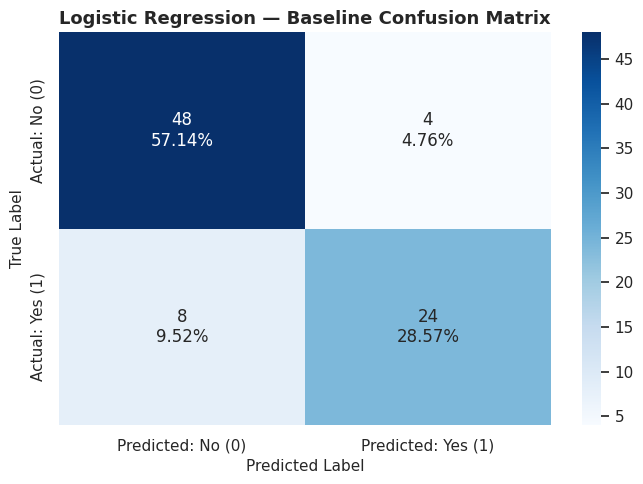


Classification Report:
              precision    recall  f1-score   support

    Cencered       0.86      0.92      0.89        52
       Death       0.86      0.75      0.80        32

    accuracy                           0.86        84
   macro avg       0.86      0.84      0.84        84
weighted avg       0.86      0.86      0.86        84



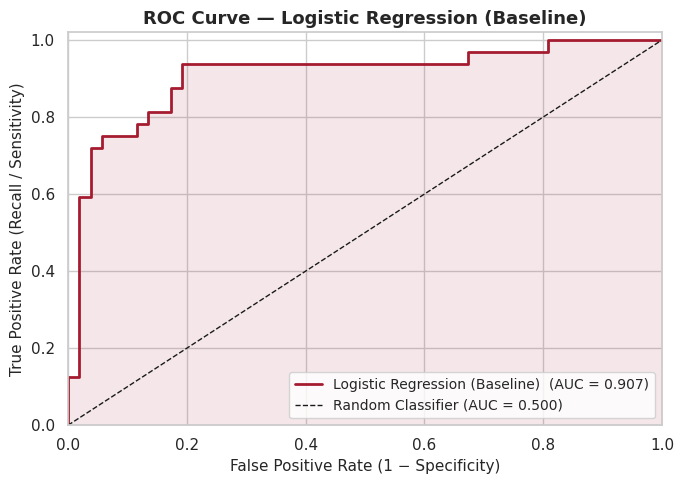

In [200]:
# @ title: Step 4a : Supervised Meaching Learning | LOGISTIC REGRESSION — CONFUSION MATRIX AND ROC CURVE

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score

make_confusion_matrix(
    lr_pipeline,
    X_test_clean,
    y_test,
    title="Logistic Regression — Baseline Confusion Matrix"
)

lr_auc = plot_roc_curve(
    lr_pipeline,
    X_test_clean,
    y_test,
    model_name="Logistic Regression (Baseline)"
)

## Limitation
Several variables, including Triglycerides, Cholesterol, Copper, Ascites, Drug, Hepatomegaly, Spiders, SGOT, and Alkaline Phosphatase, had missing data exceeding 20%. Although the class notebook recommended excluding variables with more than 20% missingness and missingness indicator, these variables were retained to preserve potantially important clinical information for mortality prediction.  Missing values were addressed through imputation within the preprocessing pipeline. Median imputation was applied to numerical variables with les than 35% missingess, while mode imputation was used for categorical variables.

However, retaining variables with substantial missingness may introduce uncertainty and potential bias, particularly if the missing data are not missing at random. The relatively small sample size and class imbalance may also affect model stability and generalizability.

## Cross-Validation Performance Interpretation

The model demonstrated relatively good discriminative performance, with a mean ROC-AUC of 0.832 (SD = 0.052) and accuracy of 0.764 (SD = 0.057). However, recall (mean = 0.636, SD = 0.150) and F1-score (mean = 0.666, SD = 0.113) showed greater variability across cross-validation folds, suggesting less consistent identification of patients with the death outcome.

Several factors may contribute to this variability, including the relatively small sample size, class imbalance, missing data patterns, and sensitivity to the classification threshold. Although missingness may have affected model stability, its contribution cannot be determined from these results alone. Further sensitivity analyses comparing different missing-data handling strategies would help assess its potential impact.

In [201]:
# @title Step 4b: Supervised Machine Learning | Decision Tree - Baseline

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", DecisionTreeClassifier(
        criterion="gini",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Train Decision Tree
dt_pipeline.fit(X_train_clean, y_train)

print("Decision Tree — Baseline (Gini, unconstrained depth)")

# Evaluate model
dt_scores = get_metrics_score(
    dt_pipeline,
    X_train_clean,
    X_test_clean,
    y_train,
    y_test
)

Decision Tree — Baseline (Gini, unconstrained depth)
Metric                    Train      Test
Accuracy                  1.000     0.679
Recall                    1.000     0.750
Precision                 1.000     0.558
F1-Score                  1.000     0.640
AUC-ROC                   1.000     0.692


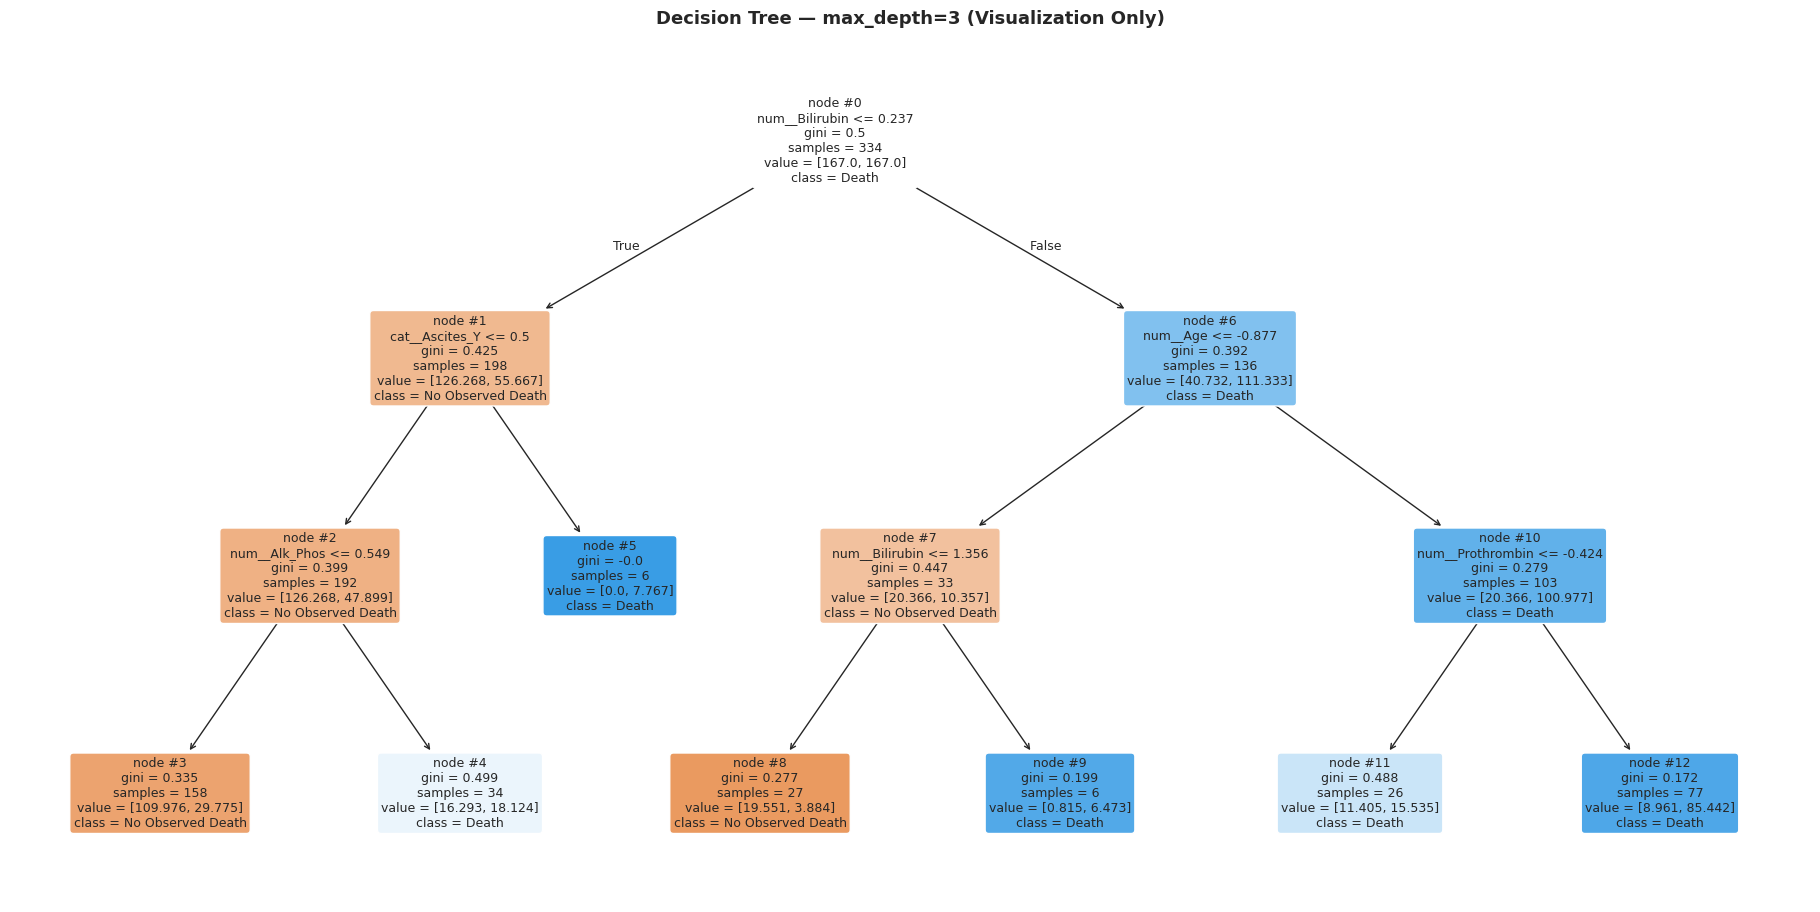

In [202]:
# @title Step 4b: Supervised Machine Learning | DECISION TREE — VISUALIZE THE TREE STRUCTURE

import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.base import clone

# 1. Create a visualization-only Decision Tree
dt_viz = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# 2. Fit using the cleaned training dataset
dt_viz.fit(X_train_clean, y_train)

# 3. Get feature names AFTER preprocessing
feature_names = (
    dt_viz.named_steps["preprocessor"]
    .get_feature_names_out()
)

# 4. Plot the tree
fig, ax = plt.subplots(figsize=(20, 10))

plot_tree(
    dt_viz.named_steps["clf"],
    feature_names=feature_names,
    class_names=["No Observed Death", "Death"],
    filled=True,
    rounded=True,
    fontsize=9,
    node_ids=True,
    ax=ax
)

ax.set_title(
    "Decision Tree — max_depth=3 (Visualization Only)",
    fontsize=13,
    fontweight="bold"
)

plt.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.92,
    bottom=0.05
)

plt.show()


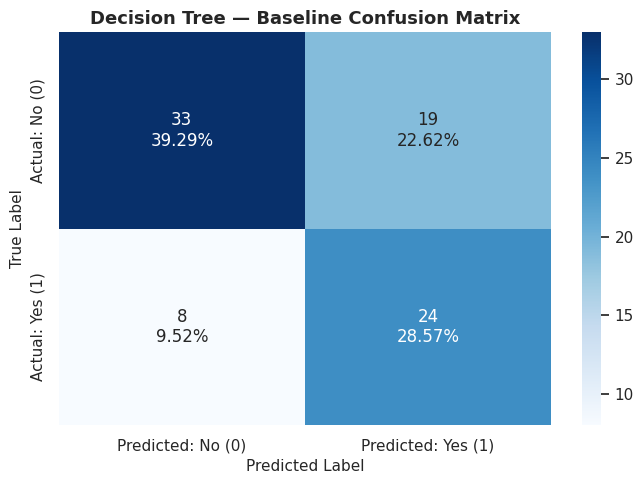


Classification Report:
              precision    recall  f1-score   support

    Cencered       0.80      0.63      0.71        52
       Death       0.56      0.75      0.64        32

    accuracy                           0.68        84
   macro avg       0.68      0.69      0.67        84
weighted avg       0.71      0.68      0.68        84



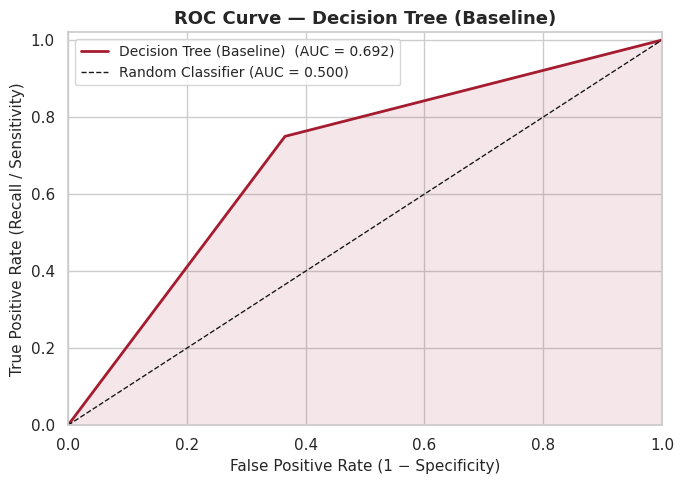

In [203]:
# @title Step 4b: Supervised Machine Learning | DECISION TREE — CONFUSION MATRIX AND ROC CURVE

make_confusion_matrix(dt_pipeline, X_test, y_test,
                      title="Decision Tree — Baseline Confusion Matrix")

dt_auc = plot_roc_curve(dt_pipeline, X_test, y_test,
                        model_name="Decision Tree (Baseline)")

In [204]:
# @title Step 4c: Supervised Machine Learning | RANDOM FOREST — BASELINE MODEL


from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        class_weight="balanced",
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train the model
rf_pipeline.fit(X_train_clean, y_train)

# Report OOB score
oob = rf_pipeline.named_steps["clf"].oob_score_

print("Random Forest — Baseline (100 trees)")
print(f"Out-of-Bag (OOB) Score: {oob:.3f}")

# Model evaluation
rf_scores = get_metrics_score(
    rf_pipeline,
    X_train_clean,
    X_test_clean,
    y_train,
    y_test
)

Random Forest — Baseline (100 trees)
Out-of-Bag (OOB) Score: 0.763
Metric                    Train      Test
Accuracy                  1.000     0.810
Recall                    1.000     0.625
Precision                 1.000     0.833
F1-Score                  1.000     0.714
AUC-ROC                   1.000     0.870


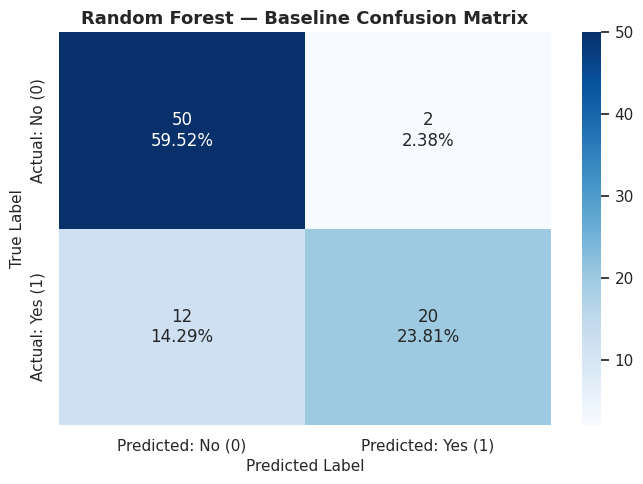


Classification Report:
              precision    recall  f1-score   support

    Cencered       0.81      0.96      0.88        52
       Death       0.91      0.62      0.74        32

    accuracy                           0.83        84
   macro avg       0.86      0.79      0.81        84
weighted avg       0.85      0.83      0.83        84



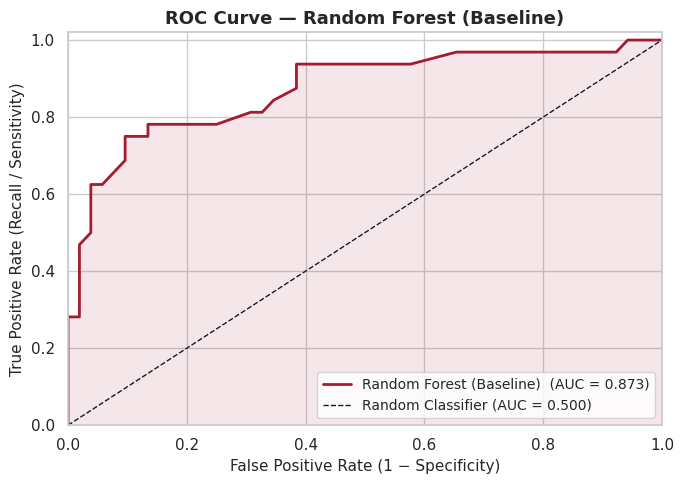

In [205]:
# @title Step 4c: Supervised Machine Learning | RANDOM FOREST — CONFUSION MATRIX AND ROC CURVE

make_confusion_matrix(rf_pipeline, X_test, y_test,
                      title="Random Forest — Baseline Confusion Matrix")

rf_auc = plot_roc_curve(rf_pipeline, X_test, y_test,
                        model_name="Random Forest (Baseline)")

In [206]:
# @title Step 4: Supervised Macine Learning | Calculate Model Evaluation Scores

# Logistic Regression
lr_scores = get_metrics_score(
    lr_pipeline,
    X_train_clean,
    X_test_clean,
    y_train,
    y_test
)

# Decision Tree
dt_scores = get_metrics_score(
    dt_pipeline,
    X_train_clean,
    X_test_clean,
    y_train,
    y_test
)

# Random Forest
rf_scores = get_metrics_score(
    rf_pipeline,
    X_train_clean,
    X_test_clean,
    y_train,
    y_test
)

print("All model evaluation scores calculated successfully!")

Metric                    Train      Test
Accuracy                  0.796     0.857
Recall                    0.814     0.750
Precision                 0.705     0.857
F1-Score                  0.755     0.800
AUC-ROC                   0.868     0.907
Metric                    Train      Test
Accuracy                  1.000     0.679
Recall                    1.000     0.750
Precision                 1.000     0.558
F1-Score                  1.000     0.640
AUC-ROC                   1.000     0.692
Metric                    Train      Test
Accuracy                  1.000     0.810
Recall                    1.000     0.625
Precision                 1.000     0.833
F1-Score                  1.000     0.714
AUC-ROC                   1.000     0.870
All model evaluation scores calculated successfully!


In [207]:

# @title Step 5: Model Performance Comparison

import pandas as pd
from IPython.display import display

# -------------------------------------------------------
# 1. Collect models and evaluation scores
# -------------------------------------------------------

all_models = {
    "Logistic Regression": (lr_pipeline, lr_scores),
    "Decision Tree": (dt_pipeline, dt_scores),
    "Random Forest": (rf_pipeline, rf_scores)
}

# -------------------------------------------------------
# 2. Create comparison table
# -------------------------------------------------------

comparison_rows = []

for model_name, (model, scores) in all_models.items():

    comparison_rows.append({
        "Model": model_name,
        "Train Accuracy": scores[0],
        "Test Accuracy": scores[1],
        "Train Recall": scores[2],
        "Test Recall": scores[3],
        "Train Precision": scores[4],
        "Test Precision": scores[5],
        "Train F1": scores[6],
        "Test F1": scores[7],
        "Test AUC-ROC": scores[9]
    })

comparison_df = pd.DataFrame(comparison_rows)

# -------------------------------------------------------
# 3. Calculate train-test performance gap
# -------------------------------------------------------

comparison_df["Accuracy Gap"] = (
    comparison_df["Train Accuracy"] -
    comparison_df["Test Accuracy"]
)

# -------------------------------------------------------
# 4. Sort by Test Recall
# -------------------------------------------------------

comparison_df = comparison_df.sort_values(
    by="Test AUC-ROC",
    ascending=False
).reset_index(drop=True)

# -------------------------------------------------------
# 5. Highlight highest Test Recall
# -------------------------------------------------------

def highlight_best_recall(column):
    best = column == column.max()

    return [
        "background-color: #fde8ea; font-weight: bold"
        if value else ""
        for value in best
    ]

# -------------------------------------------------------
# 6. Display comparison table
# -------------------------------------------------------

print("=" * 75)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(
    comparison_df.style
    .apply(
        highlight_best_recall,
        subset=["Test AUC-ROC"]
    )
    .format({
        col: "{:.3f}"
        for col in comparison_df.columns
        if col != "Model"
    })
)

# -------------------------------------------------------
# 7. Identify model with highest Test Recall
# -------------------------------------------------------

best_model = comparison_df.iloc[0]

print("\nModel with Highest Test AUC-ROC:")
print(f"Model: {best_model['Model']}")
print(f"Test Recall: {best_model['Test Recall']:.3f}")
print(f"Test Precision: {best_model['Test Precision']:.3f}")
print(f"Test F1: {best_model['Test F1']:.3f}")
print(f"Test AUC-ROC: {best_model['Test AUC-ROC']:.3f}")
print(f"Accuracy Gap: {best_model['Accuracy Gap']:.3f}")

MODEL PERFORMANCE COMPARISON


,Model,Train Accuracy,Test Accuracy,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Test AUC-ROC,Accuracy Gap
0,Logistic Regression,0.796,0.857,0.814,0.750,0.705,0.857,0.755,0.800,0.907,-0.061
1,Random Forest,1.000,0.810,1.000,0.625,1.000,0.833,1.000,0.714,0.870,0.190
2,Decision Tree,1.000,0.679,1.000,0.750,1.000,0.558,1.000,0.640,0.692,0.321



Model with Highest Test AUC-ROC:
Model: Logistic Regression
Test Recall: 0.750
Test Precision: 0.857
Test F1: 0.800
Test AUC-ROC: 0.907
Accuracy Gap: -0.061


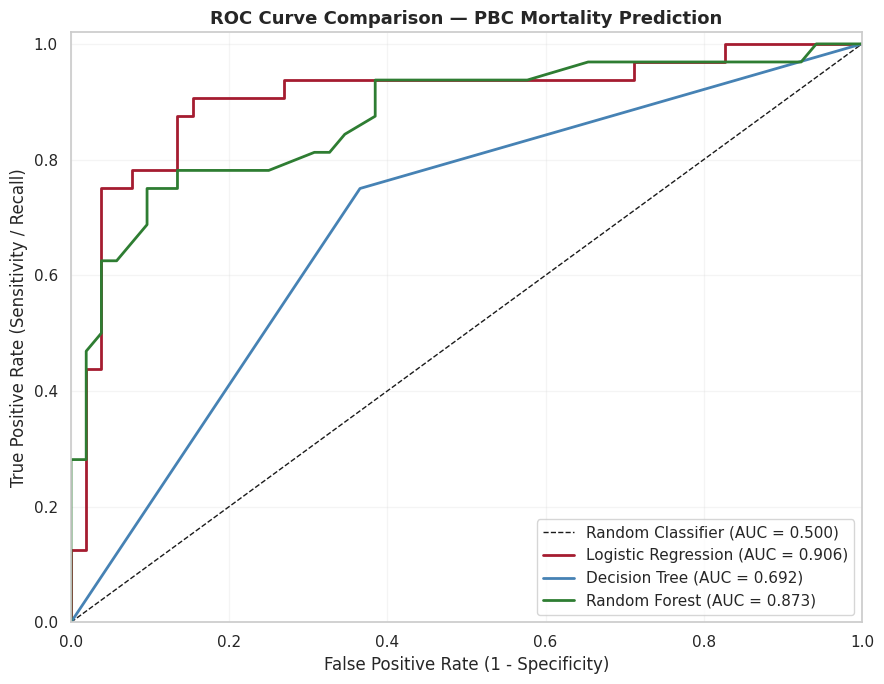

In [208]:
# @title Step 5: Combined ROC Curve — Model Comparison

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# -------------------------------------------------------
# 1. Define models
# -------------------------------------------------------

models = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline
}

# -------------------------------------------------------
# 2. Define colors
# -------------------------------------------------------

colors = {
    "Logistic Regression": "#A51C30",
    "Decision Tree": "steelblue",
    "Random Forest": "#2E7D32"
}

# -------------------------------------------------------
# 3. Create ROC plot
# -------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

# Random classifier reference line
ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Random Classifier (AUC = 0.500)"
)

# -------------------------------------------------------
# 4. Calculate ROC and AUC for each model
# -------------------------------------------------------

for model_name, model in models.items():

    # Use the same test features as model training
    if hasattr(model, "feature_names_in_"):
        X_eval = X_test[model.feature_names_in_]
    else:
        X_eval = X_test_clean

    # Predicted probability of death (Outcome = 1)
    if hasattr(model, "predict_proba"):
        positive_index = list(model.classes_).index(1)
        y_prob = model.predict_proba(X_eval)[:, positive_index]

    else:
        y_prob = model.decision_function(X_eval)

    # Calculate ROC
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob,
        pos_label=1
    )

    # Calculate AUC
    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    # Plot ROC curve
    ax.plot(
        fpr,
        tpr,
        color=colors[model_name],
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# -------------------------------------------------------
# 5. Customize visualization
# -------------------------------------------------------

ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")

ax.set_title(
    "ROC Curve Comparison — PBC Mortality Prediction",
    fontsize=13,
    fontweight="bold"
)

ax.legend(loc="lower right")
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

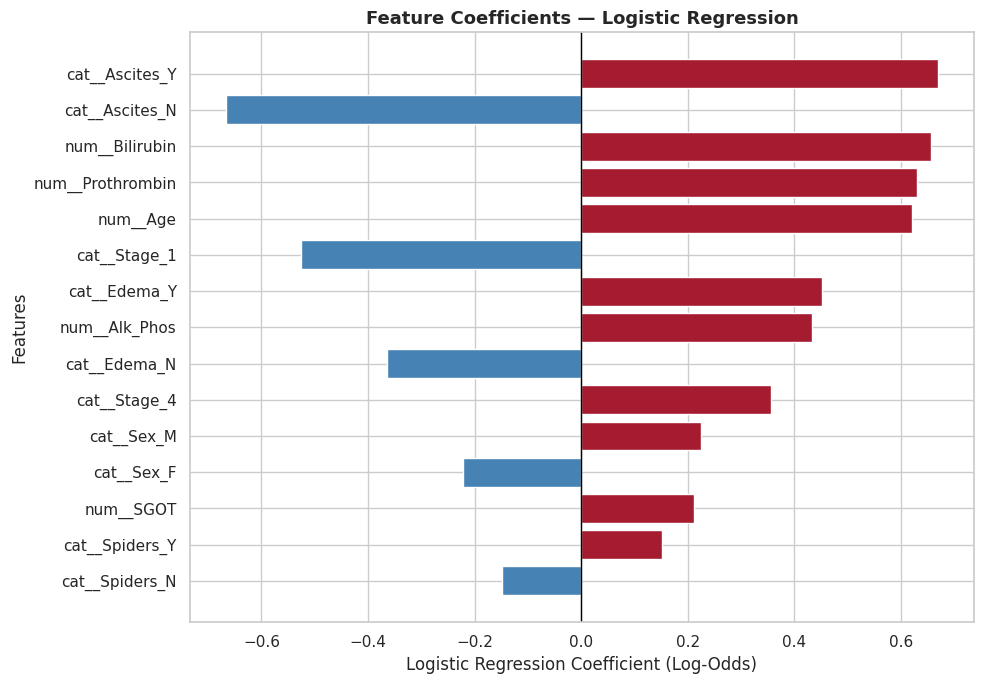


Top 10 Features — Logistic Regression


,Feature,Coefficient,Importance
0,cat__Ascites_Y,0.6708,0.6708
1,cat__Ascites_N,-0.6672,0.6672
2,num__Bilirubin,0.6569,0.6569
3,num__Prothrombin,0.6301,0.6301
4,num__Age,0.6207,0.6207
5,cat__Stage_1,-0.5249,0.5249
6,cat__Edema_Y,0.4530,0.4530
7,num__Alk_Phos,0.4339,0.4339
8,cat__Edema_N,-0.3635,0.3635
9,cat__Stage_4,0.3568,0.3568


In [209]:
# =============================================================================
# FEATURE IMPORTANCE — BEST MODEL (PLUG IN YOUR BEST MODEL BELOW)
# =============================================================================
# After reviewing the combined comparison table above, set BEST_MODEL and
# BEST_MODEL_NAME to your overall best-performing model.
#
# The model must be a tree-based estimator with feature_importances_ attribute
# (Random Forest or Bagging Classifier). If your best model is Logistic Regression
# or SVM (not tree-based), use the coefficient/permutation importance block
# instead, because the feature_importances_ attribute won't exist. In that case use
# the coefficient plot from M3-Section 6 rather than the MDI importance chart.
# =============================================================================

# ── Set your best model here ──────────────────────────────────
BEST_MODEL      = lr_pipeline                   # ← replace with your best model
BEST_MODEL_NAME = "Logistic regresssion"     # ← replace with matching label
# ─────────────────────────────────────────────────────────────

# @title Step 5: Best model | Logistic Regression Feature Importance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# 1. Select best model
# -------------------------------------------------------

BEST_MODEL = lr_pipeline
BEST_MODEL_NAME = "Logistic Regression"

# -------------------------------------------------------
# 2. Extract fitted classifier and preprocessing
# -------------------------------------------------------

classifier = BEST_MODEL.named_steps["clf"]

preprocessor = BEST_MODEL.named_steps["preprocessor"]

# -------------------------------------------------------
# 3. Get feature names after preprocessing
# -------------------------------------------------------

feature_names = preprocessor.get_feature_names_out()

# -------------------------------------------------------
# 4. Extract Logistic Regression coefficients
# -------------------------------------------------------

coefficients = classifier.coef_[0]

# -------------------------------------------------------
# 5. Create feature importance DataFrame
# -------------------------------------------------------

best_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

best_importance_df = best_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

# -------------------------------------------------------
# 6. Plot top 15 features
# -------------------------------------------------------

top_features = best_importance_df.head(15).copy()

top_features = top_features.sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

colors = [
    "#A51C30" if coef > 0 else "steelblue"
    for coef in top_features["Coefficient"]
]

ax.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors,
    edgecolor="white"
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    f"Feature Coefficients — {BEST_MODEL_NAME}",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Logistic Regression Coefficient (Log-Odds)")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

# -------------------------------------------------------
# 7. Display top 10 features
# -------------------------------------------------------

print(f"\nTop 10 Features — {BEST_MODEL_NAME}")

display(
    best_importance_df.head(10).round(4)
)

### Step 6: Interpretation of Findings and Reproducibility

Model Performance Comparison and Selection

Three supervised classification models—Logistic Regression, Decision Tree, and Random Forest—were evaluated to classify observed mortality status in patients with primary biliary cholangitis (PBC). Model performance was assessed using accuracy, precision, recall, F1-score, and ROC-AUC.

**Logistic Regression demonstrated the strongest overall performance**, achieving a test accuracy of 0.857, precision of 0.857, recall of 0.750, F1-score of 0.800, and the highest ROC-AUC of 0.907. The relatively balanced precision and recall indicate that the model was effective in distinguishing observed mortality outcomes while limiting false-positive predictions. Test accuracy was slightly higher than training accuracy, suggesting no clear evidence of overfitting based on this comparison alone.

Decision Tree achieved a test accuracy of 0.679, recall of 0.750, precision of 0.558, F1-score of 0.640, and ROC-AUC of 0.692. Although its recall was comparable to Logistic Regression, its lower precision indicated more false-positive predictions. The substantial difference between training accuracy (1.000) and testing accuracy (0.679) suggested considerable overfitting.

Random Forest achieved a test accuracy of 0.810, precision of 0.833, recall of 0.625, F1-score of 0.714, and ROC-AUC of 0.870. Although Random Forest demonstrated relatively strong precision and discriminatory performance, its lower recall indicated that 37.5% of observed mortality events were not identified. The difference between training accuracy (1.000) and testing accuracy (0.810) also suggested potential overfitting.

**Overall, Logistic Regression was selected as the preferred model based on its highest test ROC-AUC (0.907), accuracy (0.857), and F1-score (0.800).** Its balanced classification performance and relatively consistent training and testing accuracy suggest better generalization than the other evaluated models.

However, these findings should be interpreted cautiously due to substantial missingness in several predictors, the limited dataset size, and potential overfitting. Additionally, the outcome represents observed mortality status rather than mortality within a standardized follow-up period. Further validation, including external validation, would be necessary before considering clinical application.